In [74]:
import numpy as np
import matplotlib.pyplot as plt

In [75]:
from sklearn.datasets import load_diabetes

In [76]:
X, y = load_diabetes(return_X_y= True)

In [77]:
X

array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
         0.01990749, -0.01764613],
       [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
        -0.06833155, -0.09220405],
       [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
         0.00286131, -0.02593034],
       ...,
       [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
        -0.04688253,  0.01549073],
       [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
         0.04452873, -0.02593034],
       [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
        -0.00422151,  0.00306441]], shape=(442, 10))

In [78]:
from sklearn.model_selection import train_test_split

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [80]:
from sklearn.linear_model import LinearRegression

In [81]:
lr = LinearRegression()

In [82]:
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [83]:
from sklearn.metrics import r2_score

In [84]:
r2_score(y_test, lr.predict(X_test))

0.4526027629719195

In [85]:
# now doing the same thing on ridge

In [86]:
from sklearn.linear_model import Ridge

In [87]:
# fixing lambda here
rd = Ridge(alpha= 0.0001)

In [88]:
rd.fit(X_train, y_train)

,alpha,0.0001
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [89]:
r2_score(y_test, rd.predict(X_test))

0.4526998154220099

In [90]:
rd2 = Ridge(alpha= 0.001)

In [91]:
from sklearn.model_selection import cross_val_score

In [92]:
scores = cross_val_score(rd2, X_train, y_train, scoring = 'r2', cv = 5)

In [93]:
scores

array([0.54607151, 0.36426855, 0.50389898, 0.61684781, 0.22108247])

In [94]:
rd2.fit(X_train, y_train)

,alpha,0.001
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [95]:
r2_score(y_test, rd2.predict(X_test))

0.453428030101932

In [96]:
# if suppose i want to check for a series of some lambda values using gridsearchcv

In [97]:
from sklearn.model_selection import GridSearchCV

In [98]:
rdreg = Ridge()

In [99]:
param = {'alpha' : [0.001, 0.01, 1, 10, 100]}

In [100]:
grid_search_cv = GridSearchCV(
                                estimator= rdreg,
                                param_grid= param,
                                cv= 5,
                                scoring= 'r2'
)

In [101]:
grid_search_cv.fit(X_train, y_train)

,estimator,Ridge()
,param_grid,"{'alpha': [0.001, 0.01, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,0.01


In [102]:
import pandas as pd

In [103]:
df = pd.DataFrame(grid_search_cv.cv_results_)

In [104]:
df

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.002883,0.000923,0.001741,0.000376,0.001,{'alpha': 0.001},0.546072,0.364269,0.503899,0.616848,0.221082,0.450434,0.141227,2
1,0.002699,0.001266,0.001338,0.000299,0.010,{'alpha': 0.01},0.540973,0.372028,0.500391,0.612714,0.237522,0.452726,0.133027,1
2,0.001879,0.000355,0.001304,0.000258,1.000,{'alpha': 1},0.435422,0.331292,0.434621,0.447666,0.252206,0.380242,0.076599,3
3,0.001864,0.000343,0.001212,0.000207,10.000,{'alpha': 10},0.129492,0.118451,0.147947,0.129467,0.017320,0.108535,0.046581,4
4,0.001499,0.000088,0.001029,0.000091,100.000,{'alpha': 100},0.002015,0.013850,0.016196,0.012902,-0.106698,-0.012347,0.047428,5


In [105]:
grid_search_cv.best_estimator_

,alpha,0.01
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [106]:
grid_search_cv.best_params_

{'alpha': 0.01}

In [107]:
grid_search_cv.best_score_

np.float64(0.45272586712451907)

In [108]:
r2_score(y_test, grid_search_cv.predict(X_test))

0.4559819504579107

In [109]:
# now let's see overfitting and underfitting using a polynomial regression example

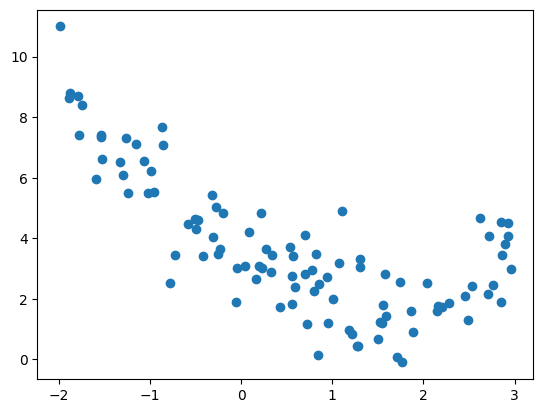

In [110]:
X1 = 5 * np.random.rand(100, 1) - 2
X2 = 0.7 * X1**2 - 2 * X1 + 3 + np.random.randn(100, 1)
plt.scatter(X1, X2)

In [111]:
from sklearn.preprocessing import PolynomialFeatures

In [112]:
from sklearn.pipeline import Pipeline

In [113]:
model = Pipeline([
                    ('poly_feats', PolynomialFeatures(degree= 16)),
                    ('ridge_model', Ridge())
])

In [114]:
params = {'ridge_model__alpha' : [0, 20, 200]}

In [115]:
grid = GridSearchCV(
                    estimator= model,
                    param_grid= params,
                    scoring= 'r2',
                    cv= 5
)

In [116]:
grid.fit(X1, X2)

,estimator,"Pipeline(step...l', Ridge())])"
,param_grid,"{'ridge_model__alpha': [0, 20, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,degree,16


In [117]:
df2 = pd.DataFrame(grid.cv_results_)

In [118]:
df2

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_ridge_model__alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.003487,0.001460,0.001557,0.000240,0,{'ridge_model__alpha': 0},0.713358,0.632961,0.601907,0.740940,0.623426,0.662518,0.054424,2
1,0.002483,0.000247,0.001603,0.000299,20,{'ridge_model__alpha': 20},0.774255,0.674135,0.862199,0.764853,0.595351,0.734158,0.091449,1
2,0.002474,0.000159,0.001568,0.000119,200,{'ridge_model__alpha': 200},0.748435,0.548411,0.768456,0.728715,0.485313,0.655866,0.115920,3


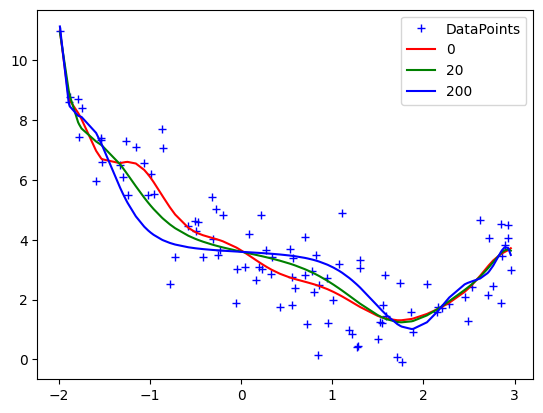

In [119]:
def get_preds_ridge(X1, X2, alpha):
    model = Pipeline([
                    ('poly_feats', PolynomialFeatures(degree= 16)),
                    ('ridge_model', Ridge(alpha))
                    ])
    model.fit(X1, X2)
    return model.predict(X1)

alphas = [0, 20, 200]
cs = ['r', 'g', 'b']

plt.plot(X1, X2, 'b+', label = 'DataPoints')
for alpha, c in zip(alphas, cs):
    preds = get_preds_ridge(X1, X2, alpha)
    plt.plot(sorted(X1[:, 0]), preds[np.argsort(X1[:, 0])], c, label = f'{alpha}')
plt.legend()